# Hedonic Pricing

We often try to predict the price of an asset from its observable characteristics. This is generally called **hedonic pricing**: How do the unit's characteristics determine its market price?

1. Clean the data `pierce_county_house_sales.csv` and perform some EDA and visualization to get to know the data set.
2. Transform your variables - particularly categorical ones - for use in your regression analysis.
3. Implement an 80/20 train-test split. Put the test data aside.
4. Build some simple linear models that include no transformations or interactions. Fit them, and determine their RMSE and $R^2$ on the both the training and test sets. Which of your models does the best?
5. Make partial correlation plots for each of the numeric variables in your model. Do you notice any significant non-linearities? 
6. Include transformations and interactions of your variables, and build a more complex model that reflects your ideas about how the features of the asset determine its value. Determine its RMSE and $R^2$ on the training and test sets. How does the more complex model your build compare to the simpler ones?
7. Summarize your results from 1 to 6. Have you learned anything about overfitting and underfitting, or model selection?
8. Use the `sklearn.linear_model.Lasso` to regularize your model and select the most predictive features. Which does it select? What are the RMSE and $R^2$? We'll cover the Lasso later in detail in class.

---

## *Phase 1: Solution without AI

Complete all questions in the following cells without generative AI. Then commit and push the
notebook before beginning Phase 2.

**Declaration:** I completed this version without generative AI.

**Student(s):** Micaiah Lee, Payton Gergen, Fal Elgizouli

**Date:** Nov 9, 2026

In [2]:
# Your Phase 1 solution to the problem goes here.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

DATA_DIR = Path("data")
df = pd.read_csv(DATA_DIR / "pierce_county_house_sales.csv")
df.head()



,sale_date,sale_price,house_square_feet,attic_finished_square_feet,basement_square_feet,attached_garage_square_feet,detached_garage_square_feet,fireplaces,hvac_description,exterior,interior,stories,roof_cover,year_built,bedrooms,bathrooms,waterfront_type,view_quality,utility_sewer
0,2020-01-02,380000,2157,0,0,528,0,0,Warm and Cool Air Zone,Frame Siding,Drywall,2,Composition Shingle,1993,3,3,NaN,NaN,SEWER/SEPTIC INSTALLED
1,2020-01-02,383000,2238,0,0,396,0,0,Forced Air,Frame Siding,Drywall,2,Composition Shingle,2017,4,3,NaN,NaN,SEWER/SEPTIC INSTALLED
2,2020-01-01,419900,1452,0,0,0,0,1,Forced Air,Frame Siding,Drywall,1,Built Up Rock,1965,3,2,NaN,NaN,SEWER/SEPTIC INSTALLED
3,2020-01-02,251660,832,0,0,0,0,0,Forced Air,Frame Vinyl,Drywall,1,Composition Shingle,1919,2,1,NaN,NaN,SEWER/SEPTIC INSTALLED
4,2020-01-02,500000,1780,0,384,484,0,1,Forced Air,Frame Siding,Drywall,1,Composition Shingle,1955,3,2,NaN,NaN,SEWER/SEPTIC INSTALLED


1. Clean the data `pierce_county_house_sales.csv` and perform some EDA and visualization to get to know the data set.

sale_price: mean: 461233.1915070774, median: 416500.0, stdev: 236083.34285437767
house_square_feet: mean: 1879.9419531342928, median: 1774.0, stdev: 760.4190083770211
attic_finished_square_feet: mean: 24.9458784346378, median: 0.0, stdev: 102.06641703009399
basement_square_feet: mean: 167.852860711312, median: 0.0, stdev: 429.065832488046
attached_garage_square_feet: mean: 364.42512192220767, median: 420.0, stdev: 286.45401800776006
detached_garage_square_feet: mean: 38.2985012489592, median: 0.0, stdev: 164.6914709558955
fireplaces: mean: 0.8890210538836684, median: 1.0, stdev: 0.5967313814053788
stories: mean: 1.5582847626977518, median: 2.0, stdev: 0.5120554008240973
year_built: mean: 1980.4692518139645, median: 1990.0, stdev: 33.3390253103978
bedrooms: mean: 3.2779826335196858, median: 3.0, stdev: 0.8912398787293564
bathrooms: mean: 2.3171761627215415, median: 2.0, stdev: 0.8279560273730177
categorical data: ['sale_date', 'hvac_description', 'exterior', 'interior', 'roof_cover', 'w

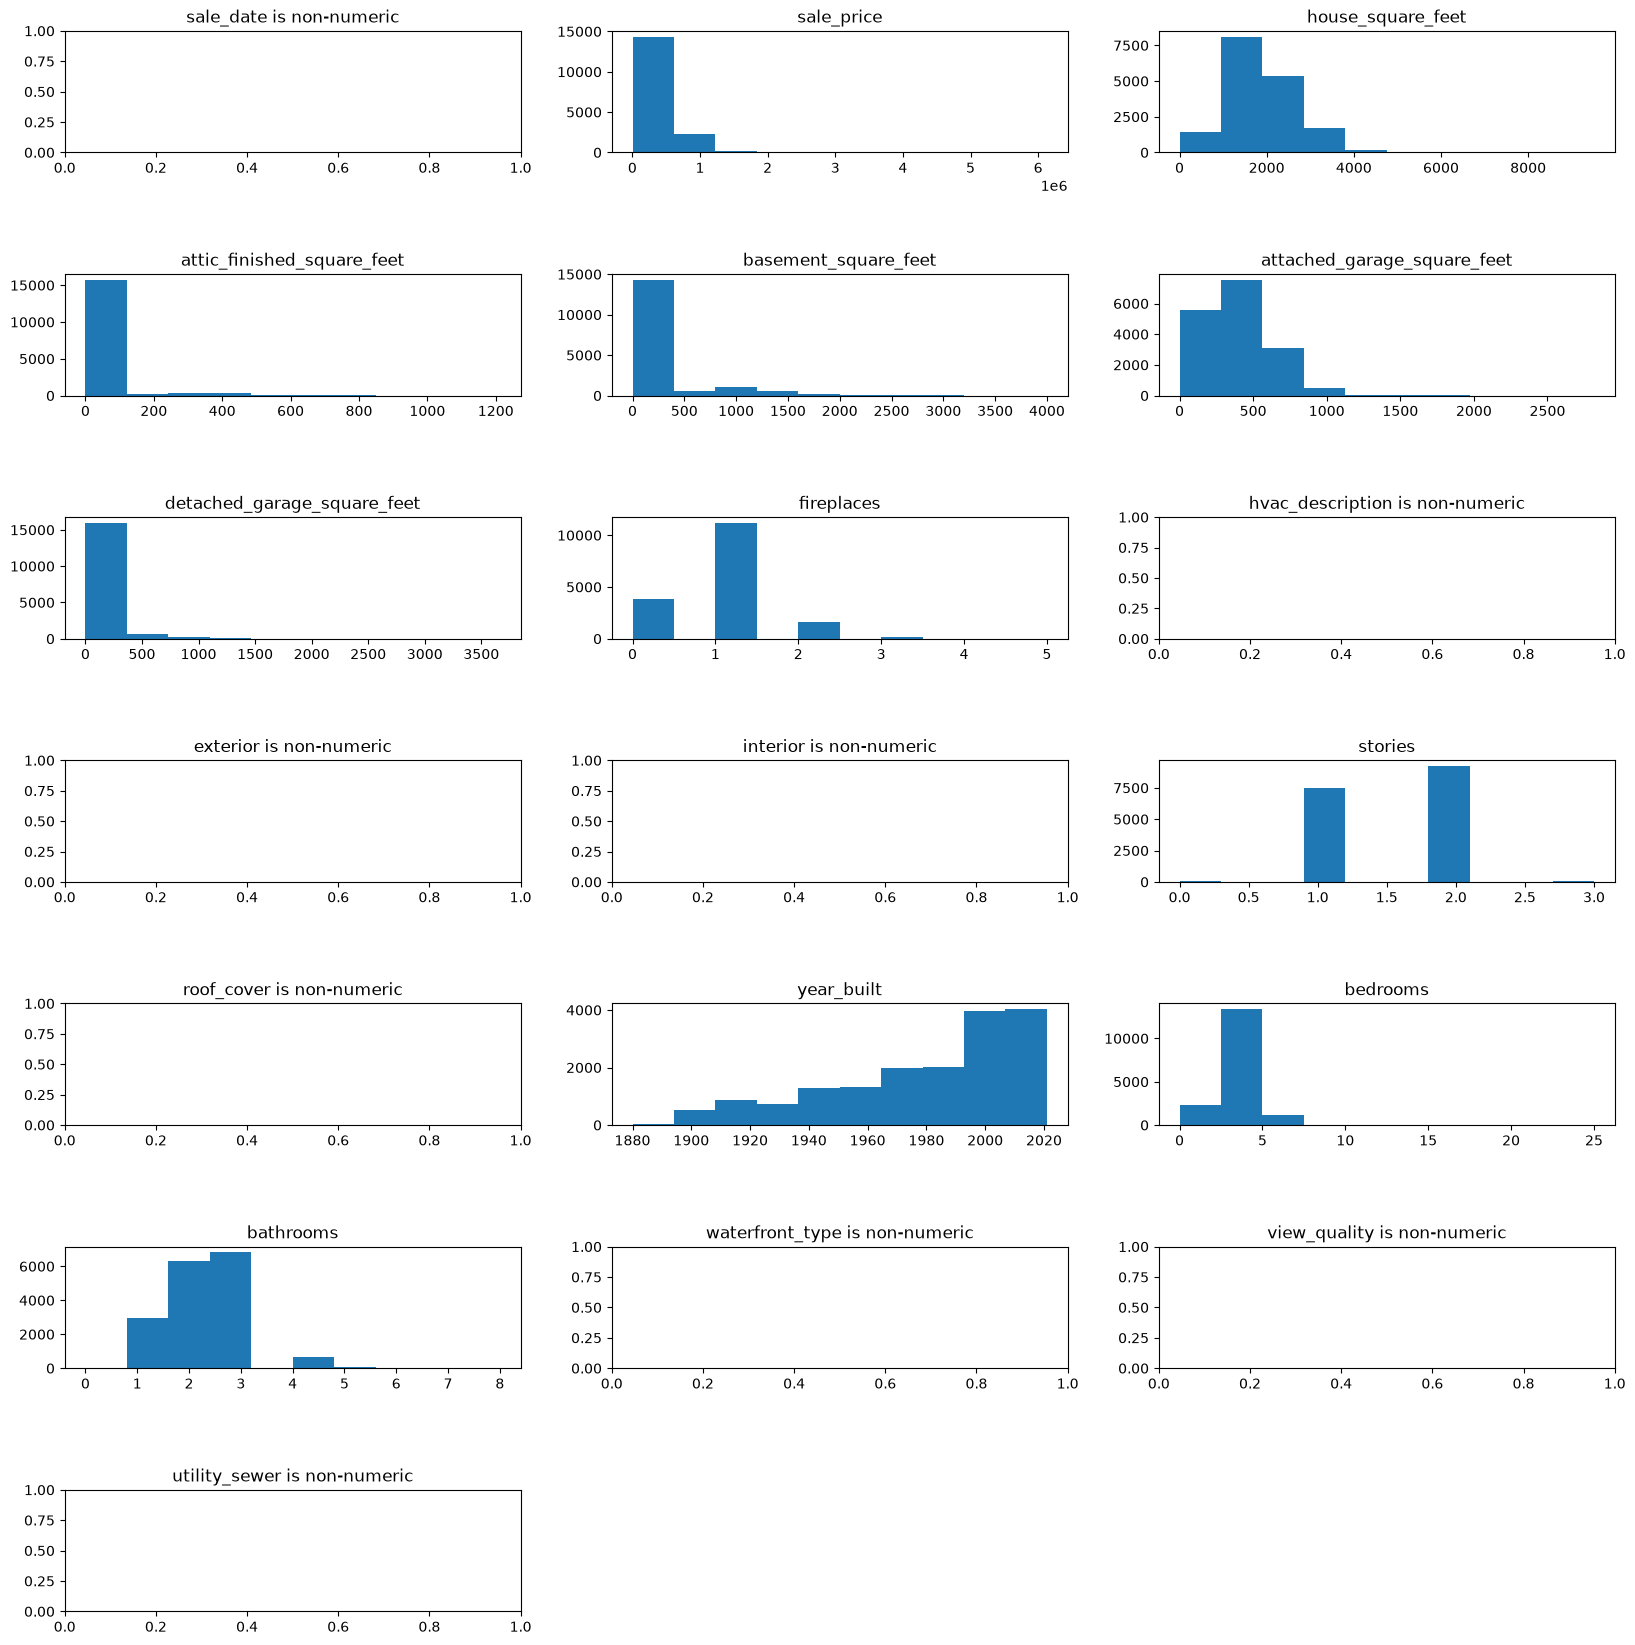

In [3]:
# EDA

# Histograms of all the numeric data
categorical = []
numeric = []

# Initialize figure
plt.figure(figsize=(20, 30))
plt.subplots_adjust(hspace=1)

# Loop through
for ind, i in enumerate(df.columns):
    ax = plt.subplot(10,3,ind+1)
    
    # If it's not a string then plot a histogram
    if df[i].dtype != "str":
        ax.hist(df[i])
        ax.set_title(f'{i}')
        print(f'{i}: mean: {df[i].mean()}, median: {df[i].median()}, stdev: {df[i].std()}')
        numeric.append(i)
    else:
        ax.set_title(f"{i} is non-numeric")
        categorical.append(i)


numeric.remove("sale_price")

# Here are the datasets needing to be transformed
print("categorical data:", categorical)
print("numeric data:", numeric)
print("sale price")

for i in categorical:
    print(i, df[i].unique())
    print(' ')

2. Transform your variables - particularly categorical ones - for use in your regression analysis.

In [4]:
# Data transformation

for ind, i in enumerate(df.columns):
    if i != "sale_date" and (df[i].dtype == "str" or df[i].dtype == "object"):
        choices = df[i].dropna().drop_duplicates().tolist()
        df[i] = df[i].fillna("Missing")
        df = pd.get_dummies(df, columns=[i], drop_first=True, dtype=int)

        print(df.head())
        print(df.isna().sum().sum())
        print(df.shape)
        print(df.select_dtypes(exclude="number").columns)


    sale_date  sale_price  house_square_feet  attic_finished_square_feet  \
0  2020-01-02      380000               2157                           0   
1  2020-01-02      383000               2238                           0   
2  2020-01-01      419900               1452                           0   
3  2020-01-02      251660                832                           0   
4  2020-01-02      500000               1780                           0   

   basement_square_feet  attached_garage_square_feet  \
0                     0                          528   
1                     0                          396   
2                     0                            0   
3                     0                            0   
4                   384                          484   

   detached_garage_square_feet  fireplaces      exterior interior  ...  \
0                            0           0  Frame Siding  Drywall  ...   
1                            0           0  Frame Siding  

3. Implement an 80/20 train-test split. Put the test data aside.


In [5]:
# Micaiah
from sklearn.model_selection import train_test_split
df_train, df_test = train_test_split(df, test_size=0.2)

print(df_train.shape, df_test.shape)


(13451, 61) (3363, 61)


4. Build some simple linear models that include no transformations or interactions. Fit them, and determine their RMSE and $R^2$ on the both the training and test sets. Which of your models does the best?


In [6]:
# Micaiah
from sklearn.linear_model import LinearRegression
from sklearn.metrics import root_mean_squared_error


i = numeric[0]
df_train[i]

# sk_fit = LinearRegression().fit(df_train.loc[i], df_train.loc["sale_price"])

for i in numeric:
    # Define training and testing
    x_train = df_train[[i]]
    y_train = df_train[["sale_price"]]
    x_test = df_test[[i]]
    y_test = df_test[["sale_price"]]

    # Run regression
    sk_fit = LinearRegression().fit(x_train, y_train)

    y_hat_train = sk_fit.predict(x_train)
    y_hat_test = sk_fit.predict(x_test)

    RMSE_train = root_mean_squared_error(y_train, y_hat_train)
    RMSE_test = root_mean_squared_error(y_test, y_hat_test)

    print("Linear regression of", i, "versus price")
    print("Training R^2:", sk_fit.score(x_train, y_train))
    print("Training RMSE:", RMSE_train)
    print("Testing R^2:", sk_fit.score(x_test, y_test))
    print("Testing RMSE:", RMSE_test)
    print('')


Linear regression of house_square_feet versus price
Training R^2: 0.2647767953259874
Training RMSE: 207995.55881856053
Testing R^2: 0.34273512176557275
Testing RMSE: 168594.63093471655

Linear regression of attic_finished_square_feet versus price
Training R^2: 0.0007967384556164525
Training RMSE: 242477.463648418
Testing R^2: -0.003006773563250409
Testing RMSE: 208269.3971870905

Linear regression of basement_square_feet versus price
Training R^2: 0.06593576086175079
Training RMSE: 234440.60409485284
Testing R^2: 0.10812081604980184
Testing RMSE: 196393.24270431313

Linear regression of attached_garage_square_feet versus price
Training R^2: 0.08697504753642094
Training RMSE: 231785.24303162046
Testing R^2: 0.14733887385446154
Testing RMSE: 192026.76198077647

Linear regression of detached_garage_square_feet versus price
Training R^2: 0.002640151580726502
Training RMSE: 242253.68911428817
Testing R^2: 0.0015442020185947314
Testing RMSE: 207796.36621361814

Linear regression of fireplace

The model which performs the best is the linear regression of house_square_feet versus price. It had the highest R^2 out of anything and lowest RMSE out of anything.


Training R^2: 0.2743023175802287

Training RMSE: 203515.08215404884

Testing R^2: 0.28925222207793

Testing RMSE: 189199.98107073287

5. Make partial correlation plots for each of the numeric variables in your model. Do you notice any significant non-linearities? 


In [7]:
from pingouin import partial_corr
import seaborn as sns

In [8]:
numeric.append("sale_price")
numeric

['house_square_feet',
 'attic_finished_square_feet',
 'basement_square_feet',
 'attached_garage_square_feet',
 'detached_garage_square_feet',
 'fireplaces',
 'stories',
 'year_built',
 'bedrooms',
 'bathrooms',
 'sale_price']

<Axes: >

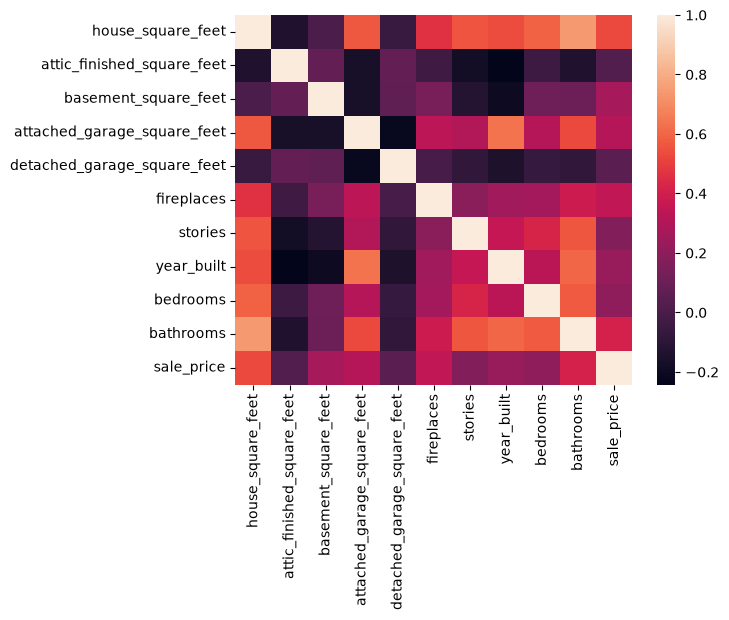

In [9]:
partial_correlations = np.zeros(shape = (11,11), dtype = float)

for i in np.arange(0,11):
    for j in np.arange(0,11):
        if i == j:
            partial_correlations[i][j] = 1
        if i != j:
            partial_correlations[i][j] = partial_corr(df, x = numeric[i], y = numeric[j]).iat[0,1]

# plt.imshow(partial_correlations, index = numeric)

df_partial_corr = pd.DataFrame(partial_correlations, index = numeric, columns = numeric)

sns.heatmap(df_partial_corr)

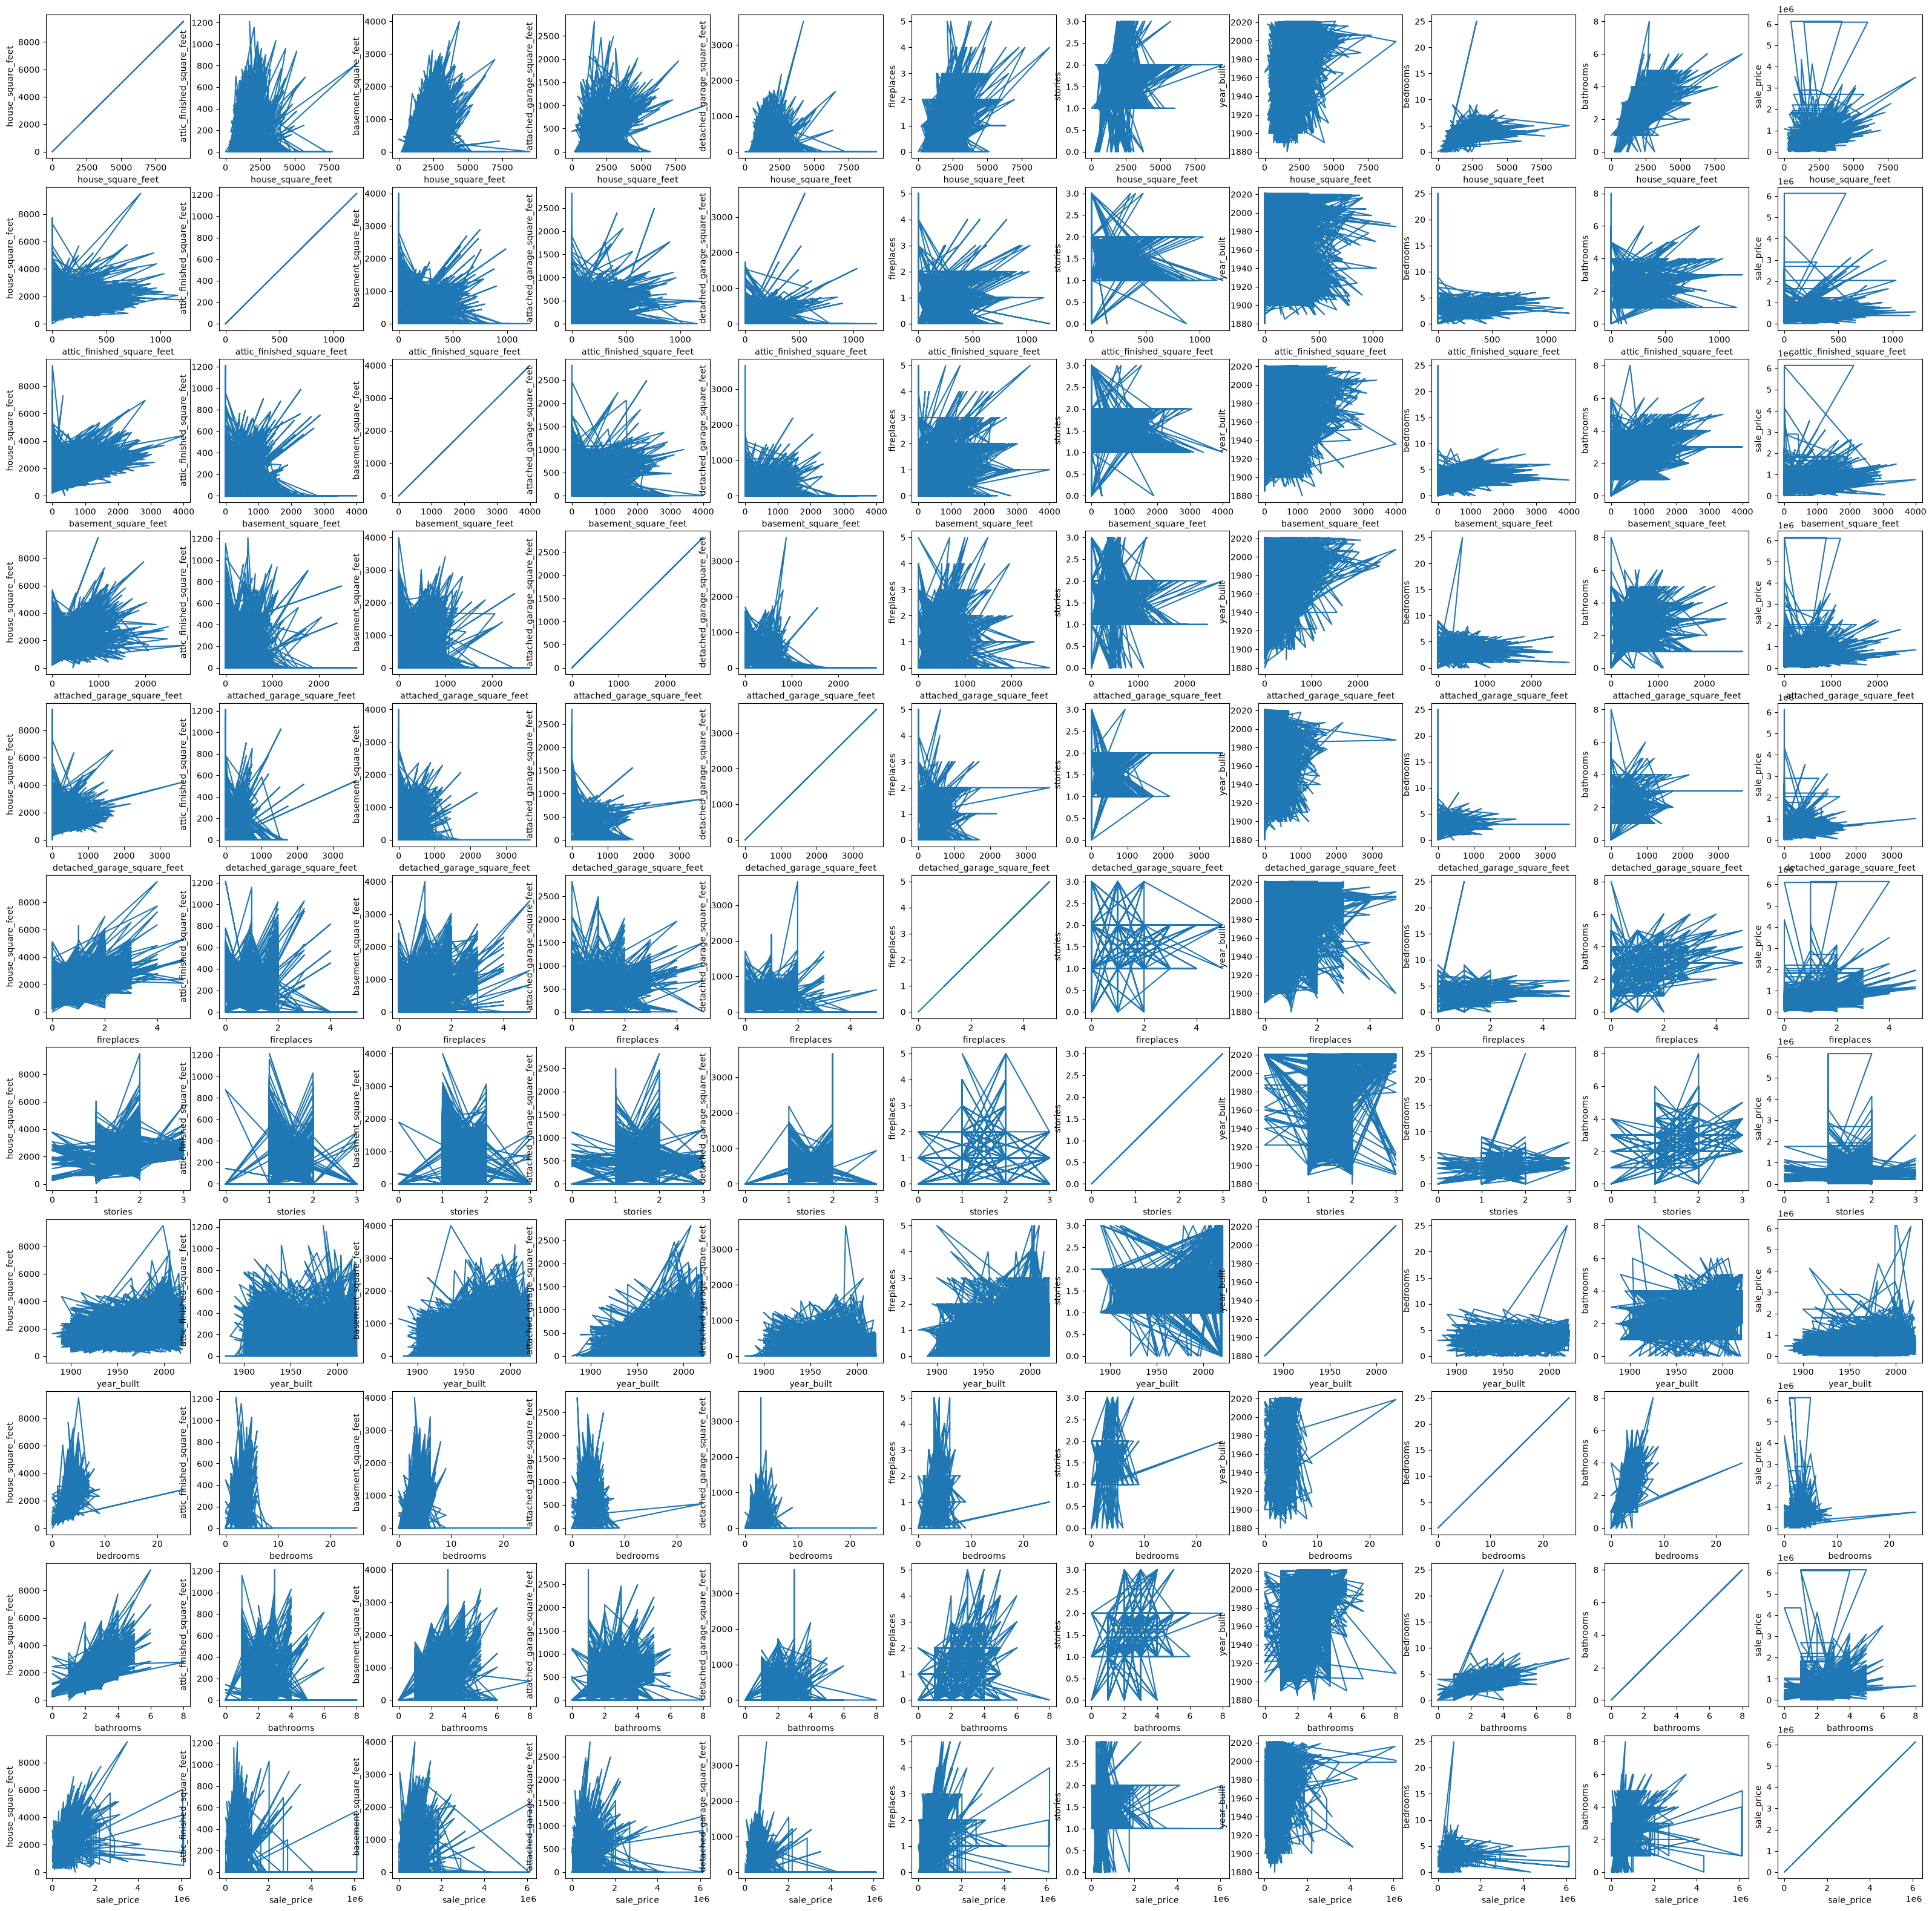

In [10]:
fig, ax = plt.subplots(11,11, figsize = (40,40))
for i in np.arange(0,11):
    for j in np.arange(0,11):
        ax[i,j].plot(df[numeric[i]], df[numeric[j]])
        ax[i,j].set_xlabel(numeric[i])
        ax[i,j].set_ylabel(numeric[j])

year_built genearlly has non-linear relationships with the other variables. Some of the integer variables, such as stories and bathrooms, have non-linear relationships as well.

6. Include transformations and interactions of your variables, and build a more complex model that reflects your ideas about how the features of the asset determine its value. Determine its RMSE and $R^2$ on the training and test sets. How does the more complex model your build compare to the simpler ones?


In [11]:
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.pipeline import make_pipeline
from datetime import datetime

In [12]:
df

,sale_date,sale_price,house_square_feet,attic_finished_square_feet,basement_square_feet,attached_garage_square_feet,detached_garage_square_feet,fireplaces,stories,year_built,...,view_quality_View Good,view_quality_View Good +,view_quality_View Lim,view_quality_View Lim +,view_quality_View Lim -,view_quality_View V-Good,utility_sewer_SEWER/SEPTIC AVAIL,utility_sewer_SEWER/SEPTIC INSTALLED,utility_sewer_SEWER/SEPTIC NO,utility_sewer_SEWER/SEPTIC NO PERC
0,2020-01-02,380000,2157,0,0,528,0,0,2,1993,...,0,0,0,0,0,0,0,1,0,0
1,2020-01-02,383000,2238,0,0,396,0,0,2,2017,...,0,0,0,0,0,0,0,1,0,0
2,2020-01-01,419900,1452,0,0,0,0,1,1,1965,...,0,0,0,0,0,0,0,1,0,0
3,2020-01-02,251660,832,0,0,0,0,0,1,1919,...,0,0,0,0,0,0,0,1,0,0
4,2020-01-02,500000,1780,0,384,484,0,1,1,1955,...,0,0,0,0,0,0,0,1,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
16809,2020-10-01,2000,3062,0,0,438,0,1,2,2004,...,0,0,0,0,0,0,0,1,0,0
16810,2020-01-08,96103,1370,0,0,400,0,1,2,2003,...,0,0,0,0,0,0,0,1,0,0
16811,2020-09-21,140000,850,360,810,0,0,1,1,1948,...,0,0,0,0,0,0,0,1,0,0
16812,2020-05-08,203000,1894,0,0,0,0,1,2,1905,...,0,0,0,0,0,0,0,1,0,0


In [13]:
df["sale_date"]

0        2020-01-02
1        2020-01-02
2        2020-01-01
3        2020-01-02
4        2020-01-02
            ...    
16809    2020-10-01
16810    2020-01-08
16811    2020-09-21
16812    2020-05-08
16813    2020-11-17
Name: sale_date, Length: 16814, dtype: str

In [14]:
dt = []
df['sale_date'] = pd.to_datetime(df['sale_date'])

In [15]:
df["sale_date"] = df['sale_date'].map(datetime.toordinal)

In [16]:
df_train_complex, df_test_complex = train_test_split(df, test_size=0.2)

In [17]:
x_train_complex = df_train_complex.drop(columns = ["sale_price"])
y_train_complex = df_train_complex["sale_price"]

x_test_complex = df_test_complex.drop(columns = ["sale_price"])
y_test_complex = df_test_complex["sale_price"]

In [18]:
complex_model = make_pipeline(PolynomialFeatures(degree = 2), LinearRegression())

complex_fit = complex_model.fit(x_train_complex, y_train_complex)

y_hat_train_complex = complex_fit.predict(x_train_complex)
y_hat_test_complex = complex_fit.predict(x_test_complex)

In [19]:
RMSE_train_complex = root_mean_squared_error(y_train_complex, y_hat_train_complex)
RMSE_test_complex = root_mean_squared_error(y_test_complex, y_hat_test_complex)

print("Training R^2:", complex_fit.score(x_train_complex, y_train_complex))
print("Training RMSE:", RMSE_train_complex)
print("Testing R^2:", complex_fit.score(x_test_complex, y_test_complex))
print("Testing RMSE:", RMSE_test_complex)

Training R^2: 0.6008447337171856
Training RMSE: 146860.7437385528
Testing R^2: 0.46781327552244045
Testing RMSE: 182407.76350924294


7. Summarize your results from 1 to 6. Have you learned anything about overfitting and underfitting, or model selection?


After performing EDA and basic visualizations on the house sales dataset, we saw what variables the dataset entails per house sale and its type. Many variables were non-numeric (type: str), which needed to be transformed into numeric values to run linear regression. We adjusted these values for the categorical variables using one-hot encoding, where NaN values were changed to 0, and basic integer values were used to represent each unique categorical choice. Then we implemented an 80/20 train-test split to prepare for our linear regression model using this data. After running and fitting some simple linear models, we found that the best-performing model was the linear regression of house_square_feet vs. price, with the highest R^2 and lowest RMSE compared to our other models. Due to using simple linear regression, our first models showed to underfit both our training and testing data. From our partial correlation plots, we found that year_built generally has non-linear relationships with the other variables. Some of the integer variables (stories/bathrooms) have non-linear relationships as well. Finally, after including transformations and interactions of our variables for a more complex linear model (multiple linear regression), we found that.We also learned about model selection in terms of picking the best model for our target predictions and how to go about it. By beginning with basic linear regression, we saw what features can indicate more predictiveness (e.g., house_square_feet) as a baseline. Furthermore, it gave us the first step to continue to improve our model by then using multiple linear regression (polynomial features) to better predict how a house's characteristics determine its market price.

8. Use the `sklearn.linear_model.Lasso` to regularize your model and select the most predictive features. Which does it select? What are the RMSE and $R^2$? We'll cover the Lasso later in detail in class.

In [20]:
from sklearn.linear_model import Lasso

In [21]:
lasso_model = make_pipeline(PolynomialFeatures(degree = 2), StandardScaler(), Lasso(max_iter = 1000))

lasso_fit = lasso_model.fit(x_train_complex, y_train_complex)

y_hat_train_lasso = lasso_fit.predict(x_train_complex)
y_hat_test_lasso = lasso_fit.predict(x_test_complex)

c:\Users\payto\OneDrive - University of Virginia\9 - Fall 2026\DS 3001\L02\L02-hedonic-pricing\.venv\Lib\site-packages\sklearn\linear_model\_coordinate_descent.py:842: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 1.048534e+14, tolerance: 7.268e+10
  model = cd_fast.enet_coordinate_descent(


In [24]:
RMSE_train_lasso = root_mean_squared_error(y_train_complex, y_hat_train_lasso)
RMSE_test_lasso = root_mean_squared_error(y_test_complex, y_hat_test_lasso)

print("Training R^2:", lasso_fit.score(x_train_complex, y_train_complex))
print("Training RMSE:", RMSE_train_lasso)
print("Testing R^2:", lasso_fit.score(x_test_complex, y_test_complex))
print("Testing RMSE:", RMSE_test_lasso)

Training R^2: 0.7031995629923175
Training RMSE: 126638.87958005721
Testing R^2: 0.35178374731572626
Testing RMSE: 201312.73914132998


In [32]:
lasso_coefs = lasso_model[-1].coef_
lasso_coefs

array([     0.        ,  20032.2577196 , 137026.53487888, ...,
        -4682.0684676 ,      0.        ,   -729.0527438 ], shape=(1891,))

In [33]:
lasso_features

array(['1', 'sale_date', 'house_square_feet', ...,
       'utility_sewer_SEWER/SEPTIC NO^2',
       'utility_sewer_SEWER/SEPTIC NO utility_sewer_SEWER/SEPTIC NO PERC',
       'utility_sewer_SEWER/SEPTIC NO PERC^2'],
      shape=(1891,), dtype=object)

In [42]:
lasso_coefs = lasso_model[-1].coef_
lasso_features = lasso_model[:-1].get_feature_names_out()
lasso_results = pd.DataFrame({"Feature" : lasso_features, "Coefficient" : lasso_coefs})
lasso_results = lasso_results.sort_values(by = "Coefficient", key = abs, ascending = False)
lasso_results.head()

,Feature,Coefficient
2,house_square_feet,137026.534879
177,house_square_feet utility_sewer_SEWER/SEPTIC I...,-111417.411997
127,house_square_feet stories,-100801.058939
611,bedrooms view_quality_View V-Good,97730.122462
166,house_square_feet waterfront_type_WF Salt,94667.175447


The top three most selective features are house_square_feet, house_square_feet + utility_sewer_SEWER/SEPTIC, and house_square_feet + stores. All of these include house_square_feet, indicating that the square feet of the house is very influential.

## *Phase 2: AI-assisted Revision
Keep Phase 1 frozen.

- **Phase 1 commit SHA ID:** [To be provided]
- **AI tool and model used:** [To be provided]

### *Prompts used

1. [Paste prompt]
2. [Paste follow-up prompt]

### *AI-proposed changes


[Paste the AI's concise numbered list verbatim.]

1. ...
2. ...

### *Evaluation of AI suggestions


| Change | Decision | Reason and verification |
|---|---|---|
| 1 | Accept / modify / reject | ... |
| 2 | Accept / modify / reject | ... |

### *AI-assisted solution in full
After the evaluation of AI suggestions, incorporate the accepted revisions into your Phase 1 solution and provide the final Phase 2 solution in full in the following cells.

In [105]:
# Your Phase 2 solution to the problem goes here.


### *Reflection on AI assistance
In your own words without generative AI.

[In 150–300 words, describe the main improvements, AI mistakes or limitations, how the final solution was verified, and any remaining concerns.]